In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import yaml

In [2]:
config_path = "config_6H_SONDJ202223.yaml"
title = "first try rwanda radar"

In [3]:
with open(config_path, 'r') as f:
    try:
        setup_params = yaml.safe_load(f)
        # print(setup_params)
    except yaml.YAMLError as exc:
        print(exc)
        
logs_folder = setup_params["SETUP"]["log_folder"]

,N,CRPS,CRPS_max_4,CRPS_max_16,CRPS_avg_4,CRPS_avg_16,RMSE,EMRMSE,RALSD,MAE,OPL,OPR
0,128,0.950417,2.182098,7.883953,0.919834,0.877980,2.478613,2.451129,22.519241,1.099626,0.676067,0.202647
1,256,0.865756,2.200507,8.292958,0.856453,0.842177,2.481192,2.473730,28.822679,0.946099,0.644404,0.268191
2,384,0.850019,2.218803,8.437673,0.849502,0.848000,2.493467,2.489275,31.591295,0.911371,0.634249,0.291882
3,512,0.862292,2.185628,8.237630,0.850040,0.829987,2.474114,2.465571,28.374271,0.949607,0.646855,0.258520
4,640,0.862759,2.153251,8.048383,0.844594,0.814753,2.465321,2.450630,26.123594,0.974650,0.651308,0.234576


  Lowest CRPS = 0.712837 at N = 30336


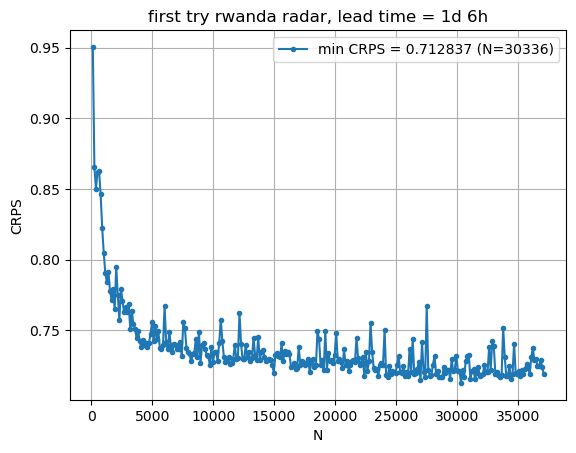

In [4]:
file_name = f"{logs_folder}/eval_validation.txt"
df = pd.read_csv(
    file_name,
    sep=r"\s+",
    header=3,
    # nrows=500,
    engine="python",
    on_bad_lines="warn",
)

display(df.head())

df["CRPS"] = pd.to_numeric(df["CRPS"], errors="coerce")
df["N"] = pd.to_numeric(df["N"], errors="coerce")

min_idx = df["CRPS"].idxmin()
min_crps = df.loc[min_idx, "CRPS"]
best_N = int(df.loc[min_idx, "N"])

print(f"  Lowest CRPS = {min_crps:.6f} at N = {best_N}")

plt.plot(df["N"], df["CRPS"], '.-',
        label=f"min CRPS = {min_crps:.6f} (N={best_N})")

plt.grid()
plt.xlabel("N")
plt.ylabel("CRPS")
plt.title(f"{title}, lead time = 1d 6h")
plt.legend()
plt.show()